# Customer Cohort Retention + Price-Volume-Mix Bridge

**Data:** [Online Retail II](https://doi.org/10.24432/C5CG6D) (UCI Machine Learning Repository, CC BY 4.0). About 1.07 million transactions from a UK online gift retailer, 1 Dec 2009 to 9 Dec 2011. Many customers are wholesalers.

**Questions:**
1. Do customers come back, and are newer cohorts better or worse?
2. What drove the year-over-year change in revenue: price, volume, mix, or new and discontinued products?

Run `python download_data.py` first. Without it, the notebook falls back to a small synthetic sample, and the numbers in the text (which come from the full dataset) won't match.

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from retail import load_transactions, clean_transactions, find_reversed_sales, add_cohorts, retention_table, pvm_bridge

pd.set_option("display.width", 200)
REAL = Path("data/online_retail_ii.csv.gz")
SAMPLE = Path("data/sample_transactions.csv")
DATA_PATH = REAL if REAL.exists() else SAMPLE
print("Using:", DATA_PATH, "(SYNTHETIC SAMPLE)" if DATA_PATH == SAMPLE else "")

raw = load_transactions(DATA_PATH)
print(f"{len(raw):,} rows, {raw['invoice_date'].min():%Y-%m-%d} to {raw['invoice_date'].max():%Y-%m-%d}")
raw.head()

Using: data/online_retail_ii.csv.gz 


1,067,371 rows, 2009-12-01 to 2011-12-09


,invoice,stock_code,description,quantity,invoice_date,price,customer_id,country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12.0,2009-12-01 07:45:00,6.95,13085,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12.0,2009-12-01 07:45:00,6.75,13085,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12.0,2009-12-01 07:45:00,6.75,13085,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48.0,2009-12-01 07:45:00,2.10,13085,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24.0,2009-12-01 07:45:00,1.25,13085,United Kingdom


## 1. Cleaning

Each rule in `clean_transactions` is applied one at a time so the log shows exactly what it removed.

In [2]:
df, cleaning_log = clean_transactions(raw)
cleaning_log

,step,rows_removed,rows_left
0,Raw rows,0,1067371
1,Exact duplicate rows,34335,1033036
2,Sales reversed by a later cancellation,6332,1026704
3,Cancellations (invoice starts with C),19104,1007600
4,Quantity <= 0,3393,1004207
5,Price <= 0,2625,1001582
6,Missing customer ID,228488,773094
7,Non-product stock codes,2696,770398


### Reviewing the cleaning rules

**Cancellations.** The obvious rule is to drop invoices starting with "C". But that only removes the *refund* line and leaves the original sale in the data, so revenue is overstated. The two largest sales in the whole dataset show why this matters:

In [3]:
dedup = raw.drop_duplicates()
big = dedup[dedup["invoice"].isin(["581483", "C581484", "541431", "C541433"])]
big.assign(line_value=big["quantity"] * big["price"])[["invoice", "description", "quantity", "price", "line_value", "customer_id", "invoice_date"]]

,invoice,description,quantity,price,line_value,customer_id,invoice_date
587080,541431,MEDIUM CERAMIC TOP STORAGE JAR,74215.0,1.04,77183.6,12346,2011-01-18 10:01:00
587085,C541433,MEDIUM CERAMIC TOP STORAGE JAR,-74215.0,1.04,-77183.6,12346,2011-01-18 10:17:00
1065882,581483,"PAPER CRAFT , LITTLE BIRDIE",80995.0,2.08,168469.6,16446,2011-12-09 09:15:00
1065883,C581484,"PAPER CRAFT , LITTLE BIRDIE",-80995.0,2.08,-168469.6,16446,2011-12-09 09:27:00


In [4]:
is_cancel = dedup["invoice"].str.upper().str.startswith("C", na=False)
sales = dedup[~is_cancel & (dedup["quantity"] > 0) & (dedup["price"] > 0)]
gross = (sales["quantity"] * sales["price"]).sum()
cancelled_value = -(dedup.loc[is_cancel, "quantity"] * dedup.loc[is_cancel, "price"]).sum()
reversed_idx = find_reversed_sales(dedup)
reversed_value = (dedup.loc[reversed_idx, "quantity"] * dedup.loc[reversed_idx, "price"]).sum()

print(f"Gross sales:                         £{gross:,.0f}")
print(f"Value of cancellation lines:         £{cancelled_value:,.0f} ({cancelled_value / gross:.1%} of gross)")
print(f"Sales matched to a later cancellation: {len(reversed_idx):,} lines, £{reversed_value:,.0f}")

Gross sales:                         £20,476,260
Value of cancellation lines:         £1,462,051 (7.1% of gross)
Sales matched to a later cancellation: 6,332 lines, £673,413


Both giant orders (80,995 paper craft birdies and 74,215 ceramic jars) were cancelled within about 15 minutes. Left in, they'd be the two biggest "sales" in the data and would distort any customer-level analysis. So I added a rule that removes a sale when a later cancellation reverses it exactly (same customer, product and quantity). That catches about 6,300 lines. Partial cancellations, where the quantity differs, aren't matched; that's a known limitation, so revenue is still slightly overstated.

In [5]:
print(f"Rows with no customer ID: {raw['customer_id'].isna().mean():.1%} of raw rows")
cust_rev = df.groupby("customer_id")["revenue"].sum().sort_values(ascending=False)
n = len(cust_rev)
print(f"Customers: {n:,}")
print(f"Top 1% of customers ({n // 100}) = {cust_rev.head(n // 100).sum() / cust_rev.sum():.1%} of revenue")
print(f"Top 10% of customers ({n // 10}) = {cust_rev.head(n // 10).sum() / cust_rev.sum():.1%} of revenue")
print(f"Median customer: £{cust_rev.median():,.0f}   Mean customer: £{cust_rev.mean():,.0f}")

Rows with no customer ID: 22.8% of raw rows
Customers: 5,839
Top 1% of customers (58) = 31.0% of revenue
Top 10% of customers (583) = 63.1% of revenue
Median customer: £851   Mean customer: £2,820


**Missing customer IDs.** About 23% of rows have no customer ID. They can't go into cohorts, so they're dropped for the retention analysis. But they're still real sales, so the PVM bridge (which works at the product level) keeps them.

**Wholesalers.** Revenue is very concentrated: the top 1% of customers bring in about a third of it, and the mean customer is worth over three times the median. That's why I look at retention two ways below, by customer count and by revenue.

## 2. Cohort retention

A cohort is every customer whose first purchase was in a given month. The table shows the share of each cohort that bought again N months later.

**Analysis window:** the data ends on 9 Dec 2011, so December 2011 is a partial month. Leaving it in makes every cohort look worse in whichever column lands on December 2011. I cut the cohort analysis at 30 Nov 2011.

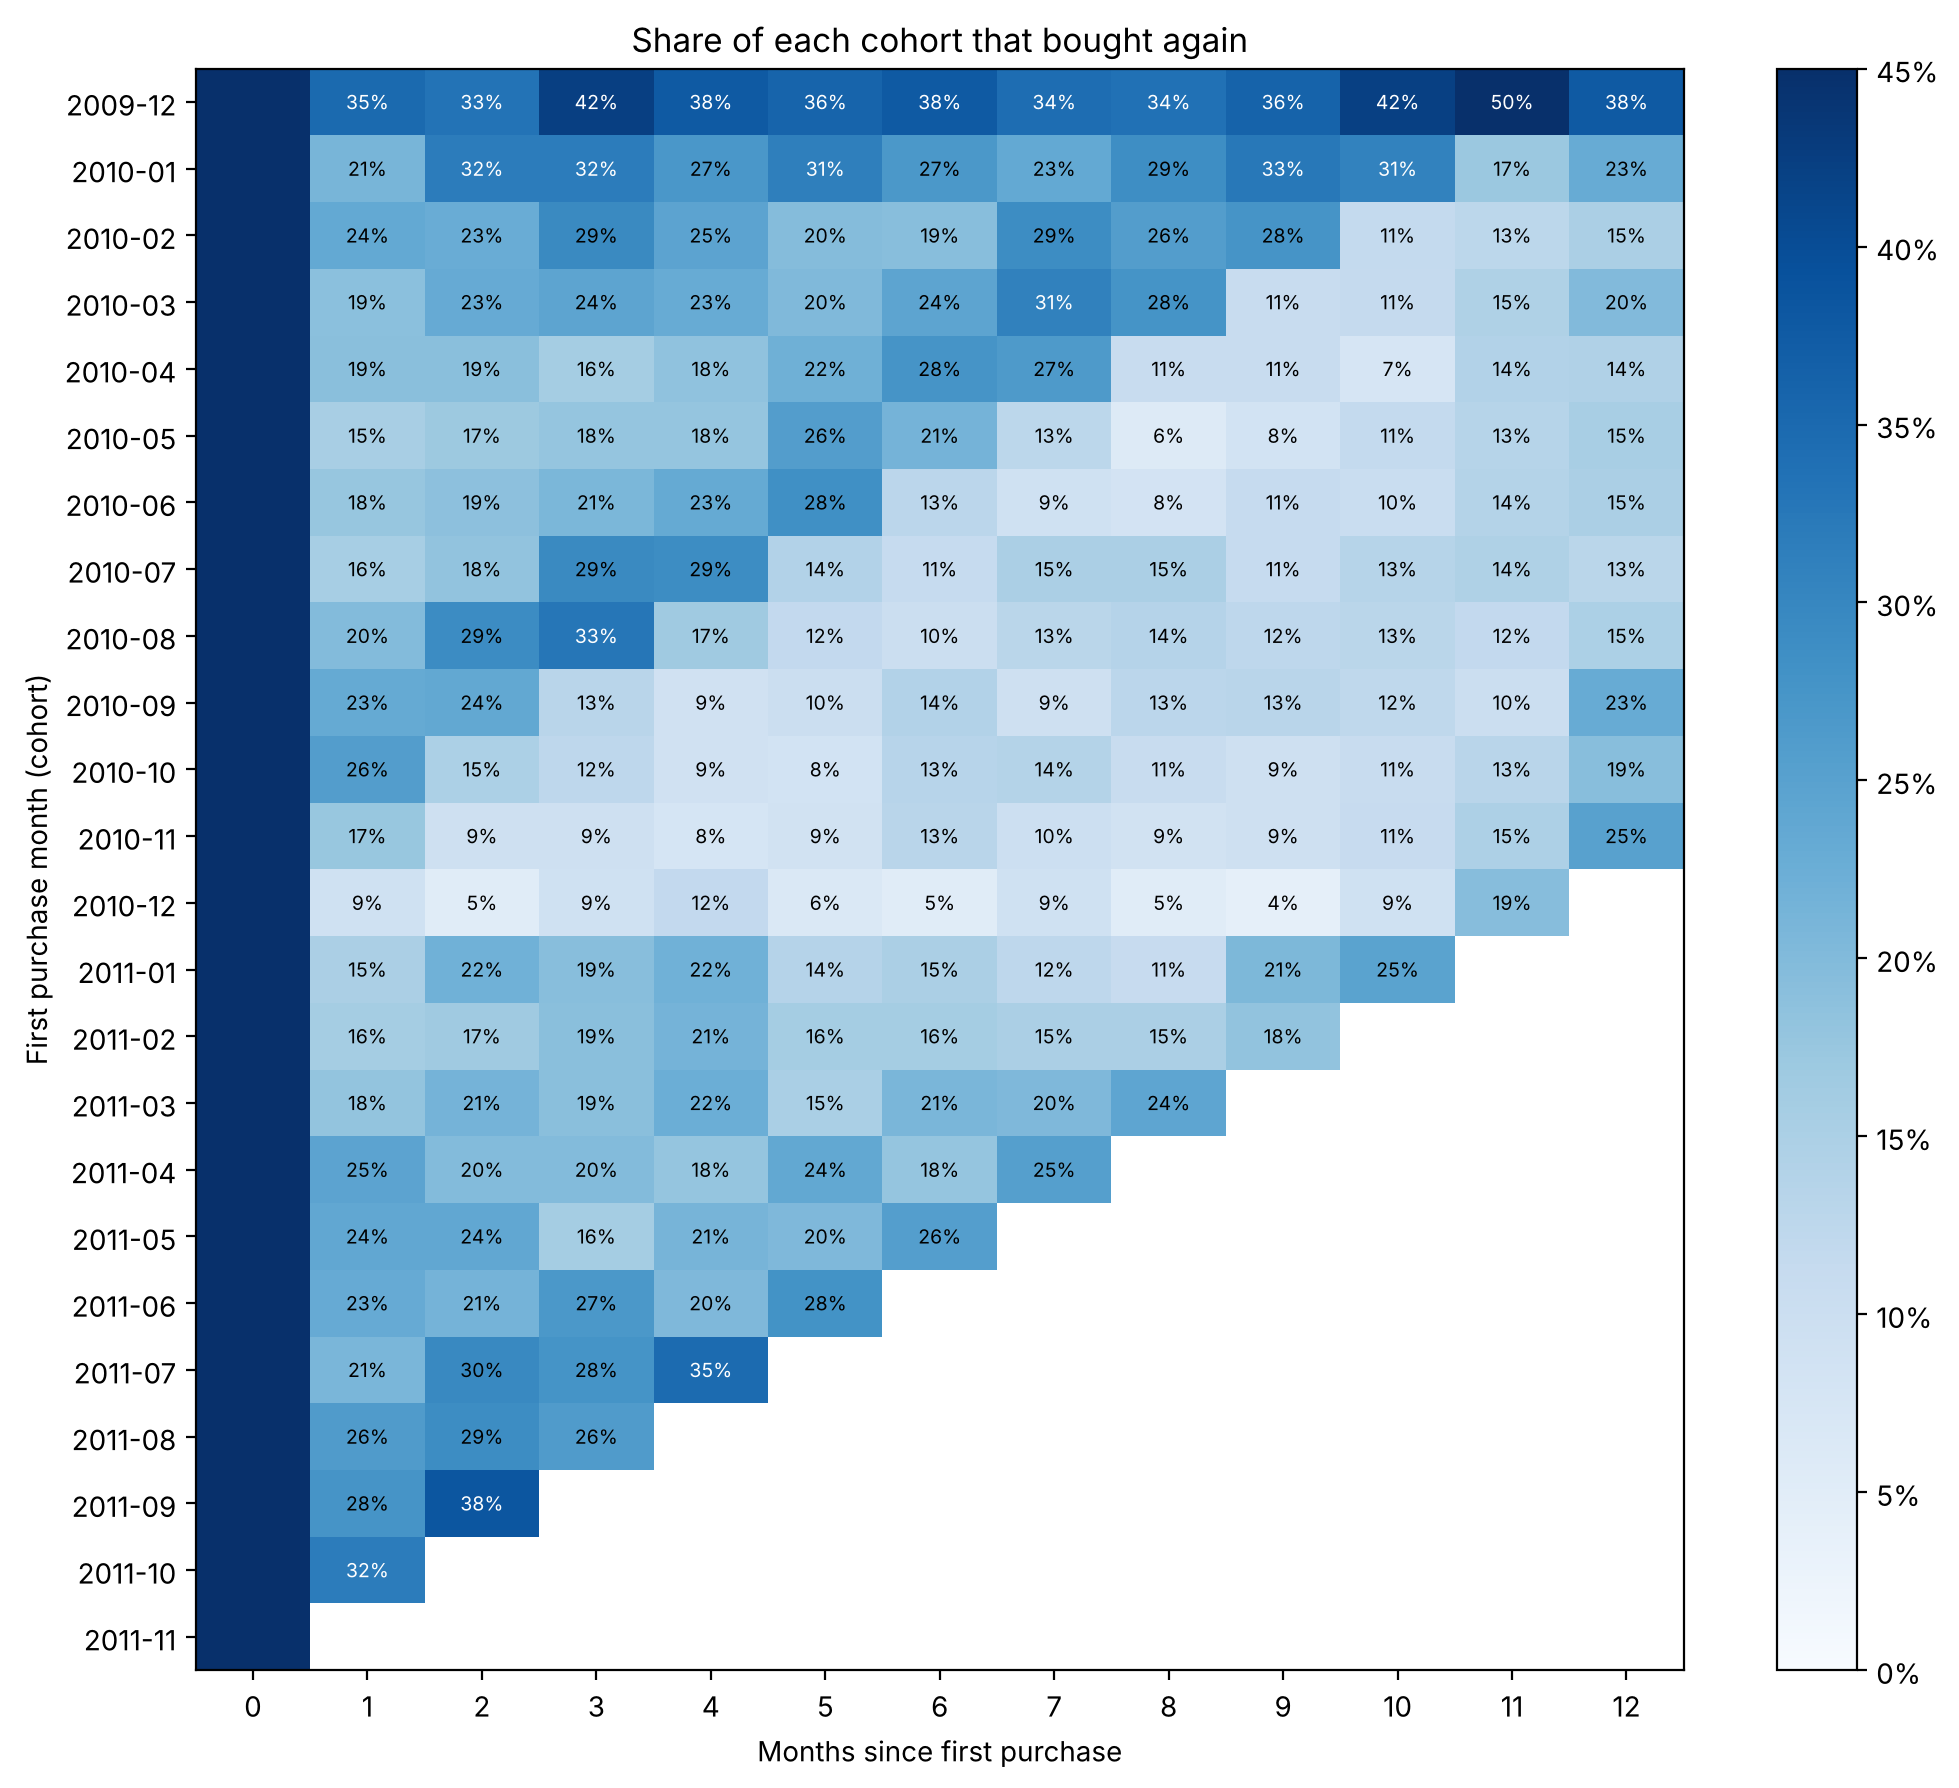

In [6]:
cohort_df = df[df["invoice_date"] < "2011-12-01"]
cohorts = add_cohorts(cohort_df)
retention = retention_table(cohorts)

first_13 = retention.loc[:, 0:12]
fig, ax = plt.subplots(figsize=(12, 0.35 * len(first_13) + 2))
im = ax.imshow(first_13.values, cmap="Blues", vmin=0, vmax=0.45, aspect="auto")
ax.set_xticks(range(first_13.shape[1]), first_13.columns)
ax.set_yticks(range(first_13.shape[0]), [str(p) for p in first_13.index])
ax.set_xlabel("Months since first purchase")
ax.set_ylabel("First purchase month (cohort)")
ax.set_title("Share of each cohort that bought again")
for i in range(first_13.shape[0]):
    for j in range(1, first_13.shape[1]):
        v = first_13.iat[i, j]
        if not np.isnan(v):
            ax.text(j, i, f"{v:.0%}", ha="center", va="center", fontsize=7, color="white" if v > 0.3 else "black")
plt.colorbar(im, ax=ax, format=lambda x, _: f"{x:.0%}")
plt.show()

In [7]:
size = cohorts.groupby("cohort_month")["customer_id"].nunique().rename("customers")
summary = pd.concat([size, retention[[1, 3, 6, 12]].add_prefix("month_")], axis=1)

def weighted(col, rows):
    s = rows[col].dropna()
    return (s * rows.loc[s.index, "customers"]).sum() / rows.loc[s.index, "customers"].sum()

later = summary.iloc[1:]   # everything except the first cohort (Dec 2009)
compare = pd.DataFrame({
    year: {f"month_{m}": weighted(f"month_{m}", later[[str(p).startswith(year) for p in later.index]]) for m in (1, 3, 6)}
    for year in ("2010", "2011")
})
print("Weighted average retention, cohorts starting in each year (excluding Dec 2009):")
print(compare.round(3))
print(f"\nDec 2009 cohort: {summary['customers'].iloc[0]:,} customers ({summary['customers'].iloc[0] / summary['customers'].sum():.0%} of all), "
      f"month-12 retention {summary['month_12'].iloc[0]:.0%} vs. {weighted('month_12', later):.0%} for later cohorts")
summary.round(3)

Weighted average retention, cohorts starting in each year (excluding Dec 2009):
          2010   2011
month_1  0.198  0.236
month_3  0.210  0.215
month_6  0.183  0.195

Dec 2009 cohort: 951 customers (16% of all), month-12 retention 38% vs. 18% for later cohorts


,customers,month_1,month_3,month_6,month_12
cohort_month,,,,,
2009-12,951,0.348,0.423,0.376,0.376
2010-01,366,0.210,0.317,0.268,0.230
2010-02,374,0.235,0.294,0.193,0.150
2010-03,441,0.188,0.243,0.243,0.200
2010-04,294,0.190,0.160,0.276,0.143
2010-05,253,0.154,0.178,0.213,0.154
2010-06,267,0.176,0.206,0.127,0.150
2010-07,187,0.155,0.294,0.112,0.128
2010-08,162,0.198,0.327,0.099,0.148


### What the retention table says

- **The first cohort isn't really a cohort.** December 2009 holds about 950 customers (16% of everyone) and keeps about 38% of them a year later, roughly double the other cohorts (about 18%). That's because the data starts in December 2009: anyone who was *already* a customer shows up as "new" that month. It's a mix of loyal existing customers, so it shouldn't be compared with real new-customer cohorts.
- **New customers are hard to keep.** For real new cohorts, only about 20 to 24% buy again the next month, and roughly 13 to 25% are still buying a year later.
- **2011 cohorts did slightly better early on.** Weighted month-1 retention is about 24% for 2011 cohorts vs. about 20% for 2010; by months 3 and 6 the gap shrinks to about a point or less. That's a small improvement, not a big change.
- **December 2010 is the weakest cohort** (77 customers, 9% back in month 1). A likely explanation is one-off holiday gift buyers, though the data can't confirm it.
- **Retention isn't a smooth decline.** It bumps up in whichever columns land in September to November, the store's busiest months, so cohorts should be compared at the same month offset, not read as a curve.
- **Recent cohorts are blank on the right** because those months haven't happened yet in the data.

### Revenue retention

Customer counts treat a £50 customer the same as a £50,000 wholesaler. This version divides each cohort's revenue in month N by its revenue in its first month.

In [8]:
rev = cohorts.groupby(["cohort_month", "months_since_first"])["revenue"].sum().unstack()
revenue_retention = rev.div(rev[0], axis=0)

cohorts_2010 = [p for p in revenue_retention.index if str(p).startswith("2010")]
print("2010 cohorts, median month-12 retention:")
print(f"  by customers: {retention.loc[cohorts_2010, 12].median():.0%}")
print(f"  by revenue:   {revenue_retention.loc[cohorts_2010, 12].median():.0%}")
revenue_retention[[1, 3, 6, 12]].round(2)

2010 cohorts, median month-12 retention:
  by customers: 15%
  by revenue:   21%


months_since_first,1,3,6,12
cohort_month,,,,
2009-12,0.56,0.55,0.44,0.50
2010-01,0.24,0.36,0.32,0.26
2010-02,0.20,0.32,0.23,0.16
2010-03,0.24,0.26,0.31,0.21
2010-04,0.15,0.19,0.28,0.13
2010-05,0.12,0.12,0.21,0.16
2010-06,0.13,0.21,0.12,0.32
2010-07,0.12,0.34,0.12,0.17
2010-08,0.19,0.39,0.09,0.17


Revenue retention is much noisier than customer retention. A few large orders can push one cohort-month to 66 to 86% (the September 2010 cohort in month 12, the January 2011 cohort in month 3). The median 2010 cohort keeps about 21% of its first-month revenue a year later, versus 15% of its customers, so the customers who stay tend to spend more than average. For a retailer this dependent on wholesalers, the revenue view is the one to manage to, and the big swings point to a handful of accounts worth tracking one by one.

## 3. Price-volume-mix bridge

### Picking fair periods

The data runs from 1 Dec 2009 to 9 Dec 2011. Comparing calendar years would be a mistake: 2011 would be missing 10 to 31 December, the peak of the holiday season, and 2009 has only one month. Instead I compare two full 12-month periods: **Dec 2009 to Nov 2010** vs. **Dec 2010 to Nov 2011**.

For PVM I keep rows without a customer ID (they're real sales; the bridge doesn't need to know who bought).

In [9]:
pvm_df, _ = clean_transactions(raw, require_customer=False)
d = pvm_df["invoice_date"]
pvm_df["period"] = np.select(
    [(d >= "2009-12-01") & (d < "2010-12-01"), (d >= "2010-12-01") & (d < "2011-12-01")],
    ["Dec09-Nov10", "Dec10-Nov11"], default=None)

calendar = pvm_df.groupby(pvm_df["invoice_date"].dt.year)["revenue"].sum()
twelve_month = pvm_df.groupby("period")["revenue"].sum()
print("Calendar years (misleading):", {k: f"£{v:,.0f}" for k, v in calendar.items()})
print(f"  2010 -> 2011: {calendar[2011] / calendar[2010] - 1:+.1%}")
print("Matching 12-month periods:  ", {k: f"£{v:,.0f}" for k, v in twelve_month.items()})
print(f"  change: {twelve_month['Dec10-Nov11'] / twelve_month['Dec09-Nov10'] - 1:+.1%}")

Calendar years (misleading): {2009: '£790,579', 2010: '£9,194,402', 2011: '£9,056,203'}
  2010 -> 2011: -1.5%
Matching 12-month periods:   {'Dec09-Nov10': '£9,218,123', 'Dec10-Nov11': '£9,377,931'}
  change: +1.7%


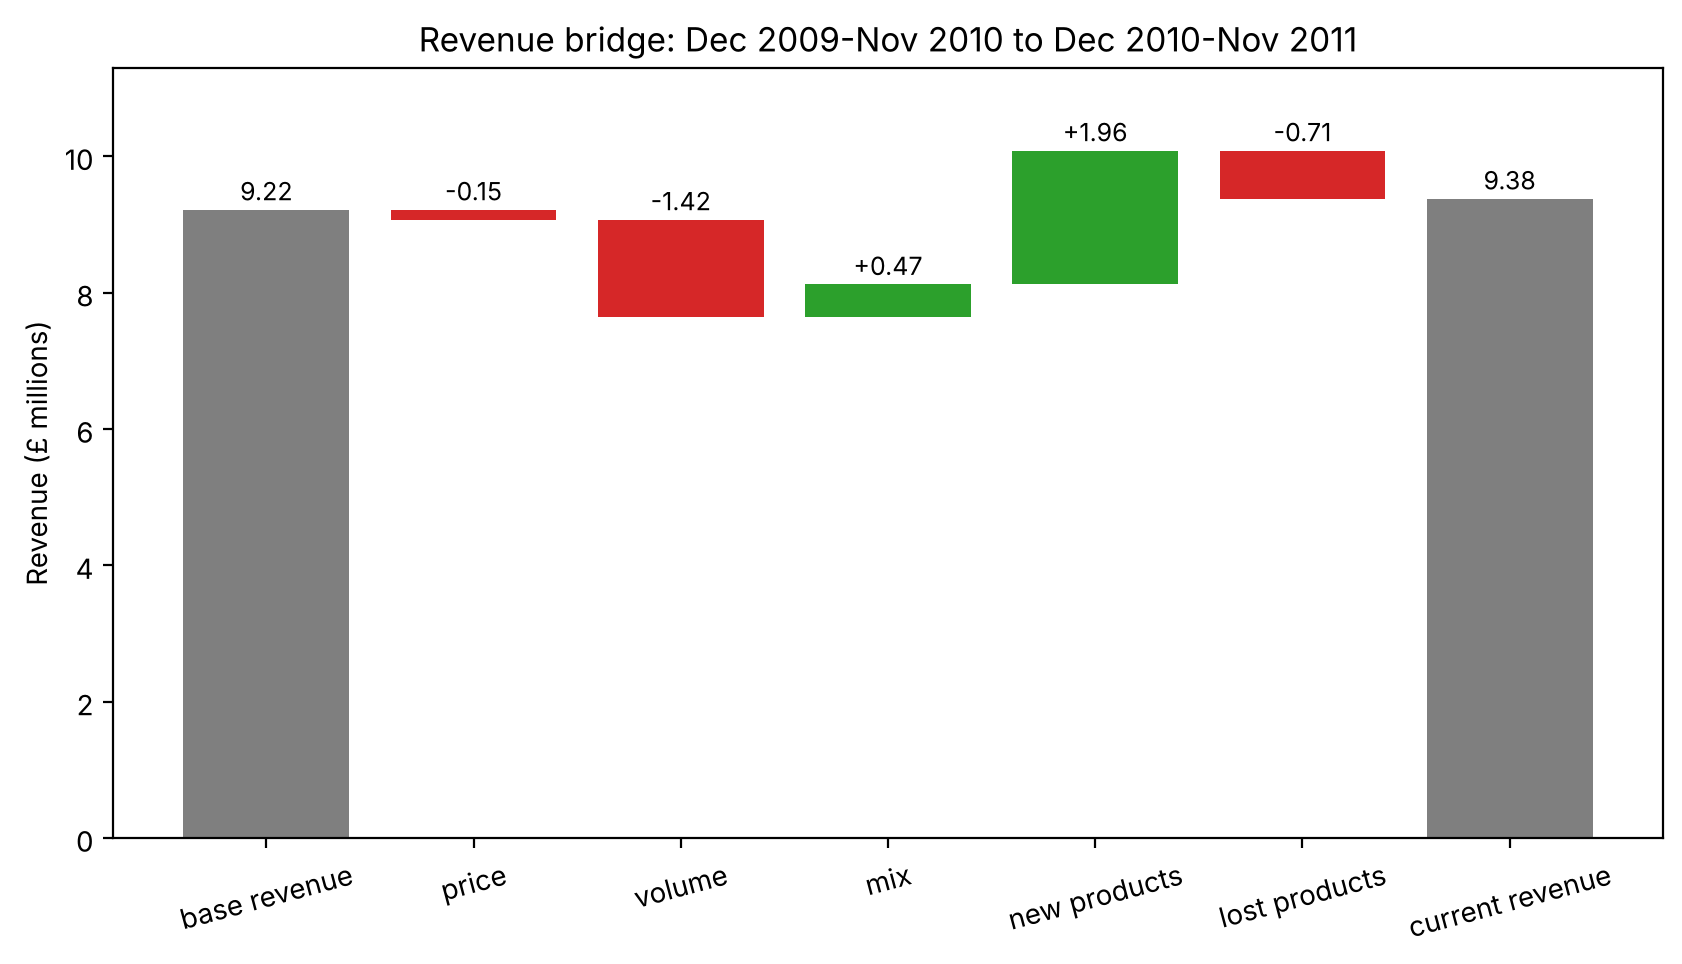

,£,% of base revenue
base_revenue,9218123.0,100.0
price,-146306.0,-1.6
volume,-1424039.0,-15.4
mix,474655.0,5.1
new_products,1962224.0,21.3
lost_products,-706727.0,-7.7
current_revenue,9377931.0,101.7


In [10]:
def plot_bridge(bridge: pd.Series, title: str = "Revenue bridge") -> None:
    """Waterfall chart for a Series ordered: base_revenue, components..., current_revenue."""
    labels = [s.replace("_", " ") for s in bridge.index]
    values = bridge.values.astype(float) / 1e6
    bottoms, heights, colors = [], [], []
    running = 0.0
    for i, v in enumerate(values):
        if i in (0, len(values) - 1):
            bottoms.append(0); heights.append(v); colors.append("tab:gray"); running = v
        else:
            bottoms.append(running if v >= 0 else running + v)
            heights.append(abs(v)); colors.append("tab:green" if v >= 0 else "tab:red")
            running += v
    fig, ax = plt.subplots(figsize=(10, 5))
    ax.bar(labels, heights, bottom=bottoms, color=colors)
    for i, v in enumerate(values):
        ax.text(i, bottoms[i] + heights[i] + 0.05, f"{v:+.2f}" if 0 < i < len(values) - 1 else f"{v:.2f}",
                ha="center", va="bottom", fontsize=9)
    ax.set_ylabel("Revenue (£ millions)")
    ax.set_title(title)
    ax.set_ylim(0, max(np.array(bottoms) + np.array(heights)) * 1.12)
    plt.xticks(rotation=15)
    plt.show()

bridge = pvm_bridge(pvm_df, period_col="period", base="Dec09-Nov10", current="Dec10-Nov11")
plot_bridge(bridge, "Revenue bridge: Dec 2009-Nov 2010 to Dec 2010-Nov 2011")
pd.DataFrame({"£": bridge.round(0), "% of base revenue": (bridge / bridge.iloc[0] * 100).round(1)})

In [11]:
sub = pvm_df.dropna(subset=["period"])
by_period = sub.groupby("period").agg(revenue=("revenue", "sum"), units=("quantity", "sum"),
                                      products=("stock_code", "nunique"), invoices=("invoice", "nunique"))
by_period["avg_price_per_unit"] = by_period["revenue"] / by_period["units"]

base_products = set(sub.loc[sub["period"] == "Dec09-Nov10", "stock_code"])
current_products = set(sub.loc[sub["period"] == "Dec10-Nov11", "stock_code"])
continuing = sorted(base_products & current_products)
units = sub[sub["stock_code"].isin(continuing)].groupby("period")["quantity"].sum()
print(f"Units of continuing products: {units['Dec10-Nov11'] / units['Dec09-Nov10'] - 1:+.1%}")
print(f"Continuing products: {len(base_products & current_products):,}   "
      f"New: {len(current_products - base_products):,}   Discontinued: {len(base_products - current_products):,}")
by_period.round(2)

Units of continuing products: -16.7%
Continuing products: 3,218   New: 675   Discontinued: 976


,revenue,units,products,invoices,avg_price_per_unit
period,,,,,
Dec09-Nov10,9218122.86,5449064.0,4194,19603,1.69
Dec10-Nov11,9377930.61,5106877.0,3893,18837,1.84


### What drove the revenue change

Revenue was **roughly flat, up about 1.7%** (£9.22M to £9.38M). The bridge shows that "flat" hides two big forces pulling in opposite directions:

- **Volume: −£1.42M (−15%).** Products sold in both years moved about 17% fewer units. This is the biggest single number on the bridge and the main problem.
- **New products: +£1.96M (+21%).** About 675 new products more than made up for the lost volume. Without them, revenue would have fallen sharply.
- **Discontinued products: −£0.71M (−8%).** About 980 products from the first year weren't sold in the second.
- **Mix: +£0.47M (+5%).** Within continuing products, sales shifted toward higher-priced items.
- **Price: −£0.15M (−1.6%).** Like-for-like prices were slightly *lower*, even though average revenue per unit rose (£1.69 to £1.84). That rise came from mix and new products, not from charging more.

**Caveat:** price here is average realized price per unit, so it also moves with quantity discounts. If wholesalers bought in smaller lots, prices could look higher without a list-price change, and vice versa.

**What I'd dig into next:** the volume drop on continuing products. Is it a few big wholesale accounts buying less, or broad-based? The cohort section showed revenue is concentrated in a small group of customers, so I'd split the volume effect by customer next, and ask the business whether the new-product pipeline can keep covering for it.

## Takeaways

- **Cleaning choices change the answer.** Dropping cancellation lines alone leaves the original sales in, including two cancelled orders worth about £245k combined. Matching cancellations to the sales they reverse fixes the biggest cases.
- **Customers are hard to keep, and the first cohort is misleading.** About 20% of new customers come back the next month. The December 2009 "cohort" looks twice as loyal only because it includes customers from before the data starts.
- **Flat revenue hid a 15% volume drop on existing products,** covered by new products. Comparing calendar years instead of matching 12-month periods would have shown a decline that wasn't real.